In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import utils, stats, io_disk, plotting as pl
from cdrmip_extremes.configs import cdr_colour_dict as colour_dict, CDR_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
gsat = utils.reduce_member_tree(io_disk.load_tree(PROC_DIR, 'gsat', 'CDRMIP', model_order=CDR_MODELS))
gsat_rolling = utils.reduce_member_tree(io_disk.load_tree(PROC_DIR, 'gsat_rolling', 'CDRMIP', model_order=CDR_MODELS))
sat_difference = io_disk.load_tree(PROC_DIR, 'tas_gwl_differences', 'CDRMIP', model_order=CDR_MODELS)
sat_difference_final = io_disk.load_tree(PROC_DIR, 'tas_matching_gwl_differences', 'CDRMIP', model_order=CDR_MODELS)
crossing_years = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'crossing_years', 'CDRMIP', as_dataarray=True,model_order=CDR_MODELS)
)
gwl_matching_years = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'gwl_matching_years', 'CDRMIP', as_dataarray=True,model_order=CDR_MODELS)
)

In [4]:
member_reduced = utils.reduce_member_tree(sat_difference)
sat_diff_agreement = stats.calc_agreement(member_reduced, expt='1pctCO2-cdr')
sat_diff = utils.reduce_models(member_reduced)

In [5]:
sat_diff = {
    model: sat_diff[model]['1pctCO2-cdr'] for model in sat_diff.keys() 
}

In [6]:
member_reduced_final = utils.reduce_member_tree(sat_difference_final,drop_coords=['gwl'])
sat_diff_agreement_final = stats.calc_agreement(member_reduced_final, expt='1pctCO2-cdr',drop_coords=['gwl'])
sat_diff_final = utils.reduce_models(member_reduced_final,drop_coords=['gwl'])

sat_diff_final = {
    model: sat_diff_final[model]['1pctCO2-cdr'] for model in sat_diff_final.keys() 
}

In [7]:
CO2 = utils.build_co2_path()
co2 = CO2.assign_coords(year=CO2.year - 100)

## Plot

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/main/Figure_1.jpg


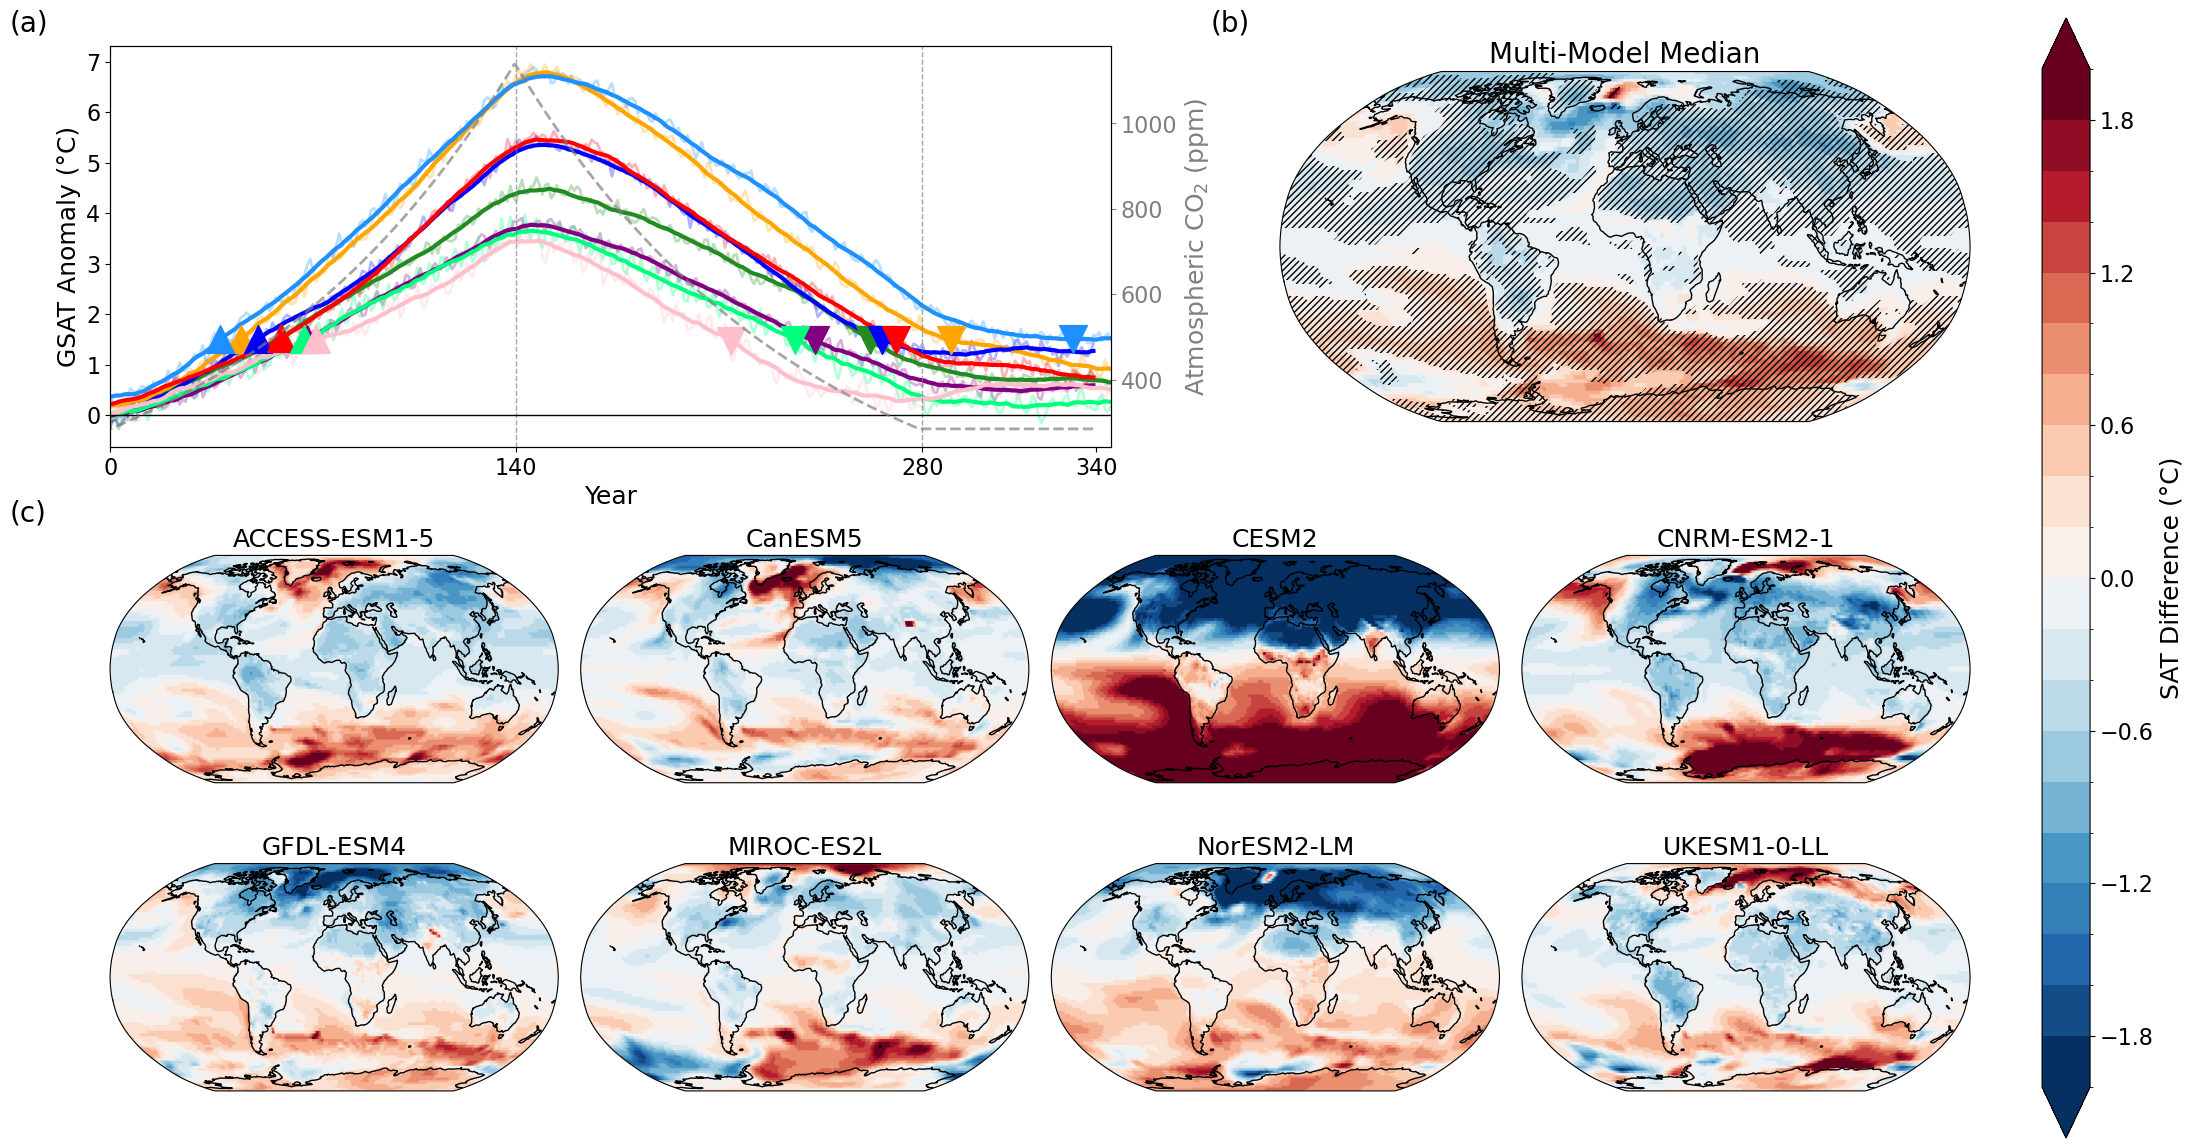

In [7]:
fig = pl.plot_gwl_diff_with_timeseries(
    gsat_rolling,
    sat_diff,
    colour_dict,
    raw_tree=gsat,
    crossing_years = crossing_years,
    agreement = sat_diff_agreement,
    gwl=1.5,
    co2=co2,
    fig_dir = FIG_DIR, folder = 'main', file_name = 'figure_1.jpg'
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S32.jpg


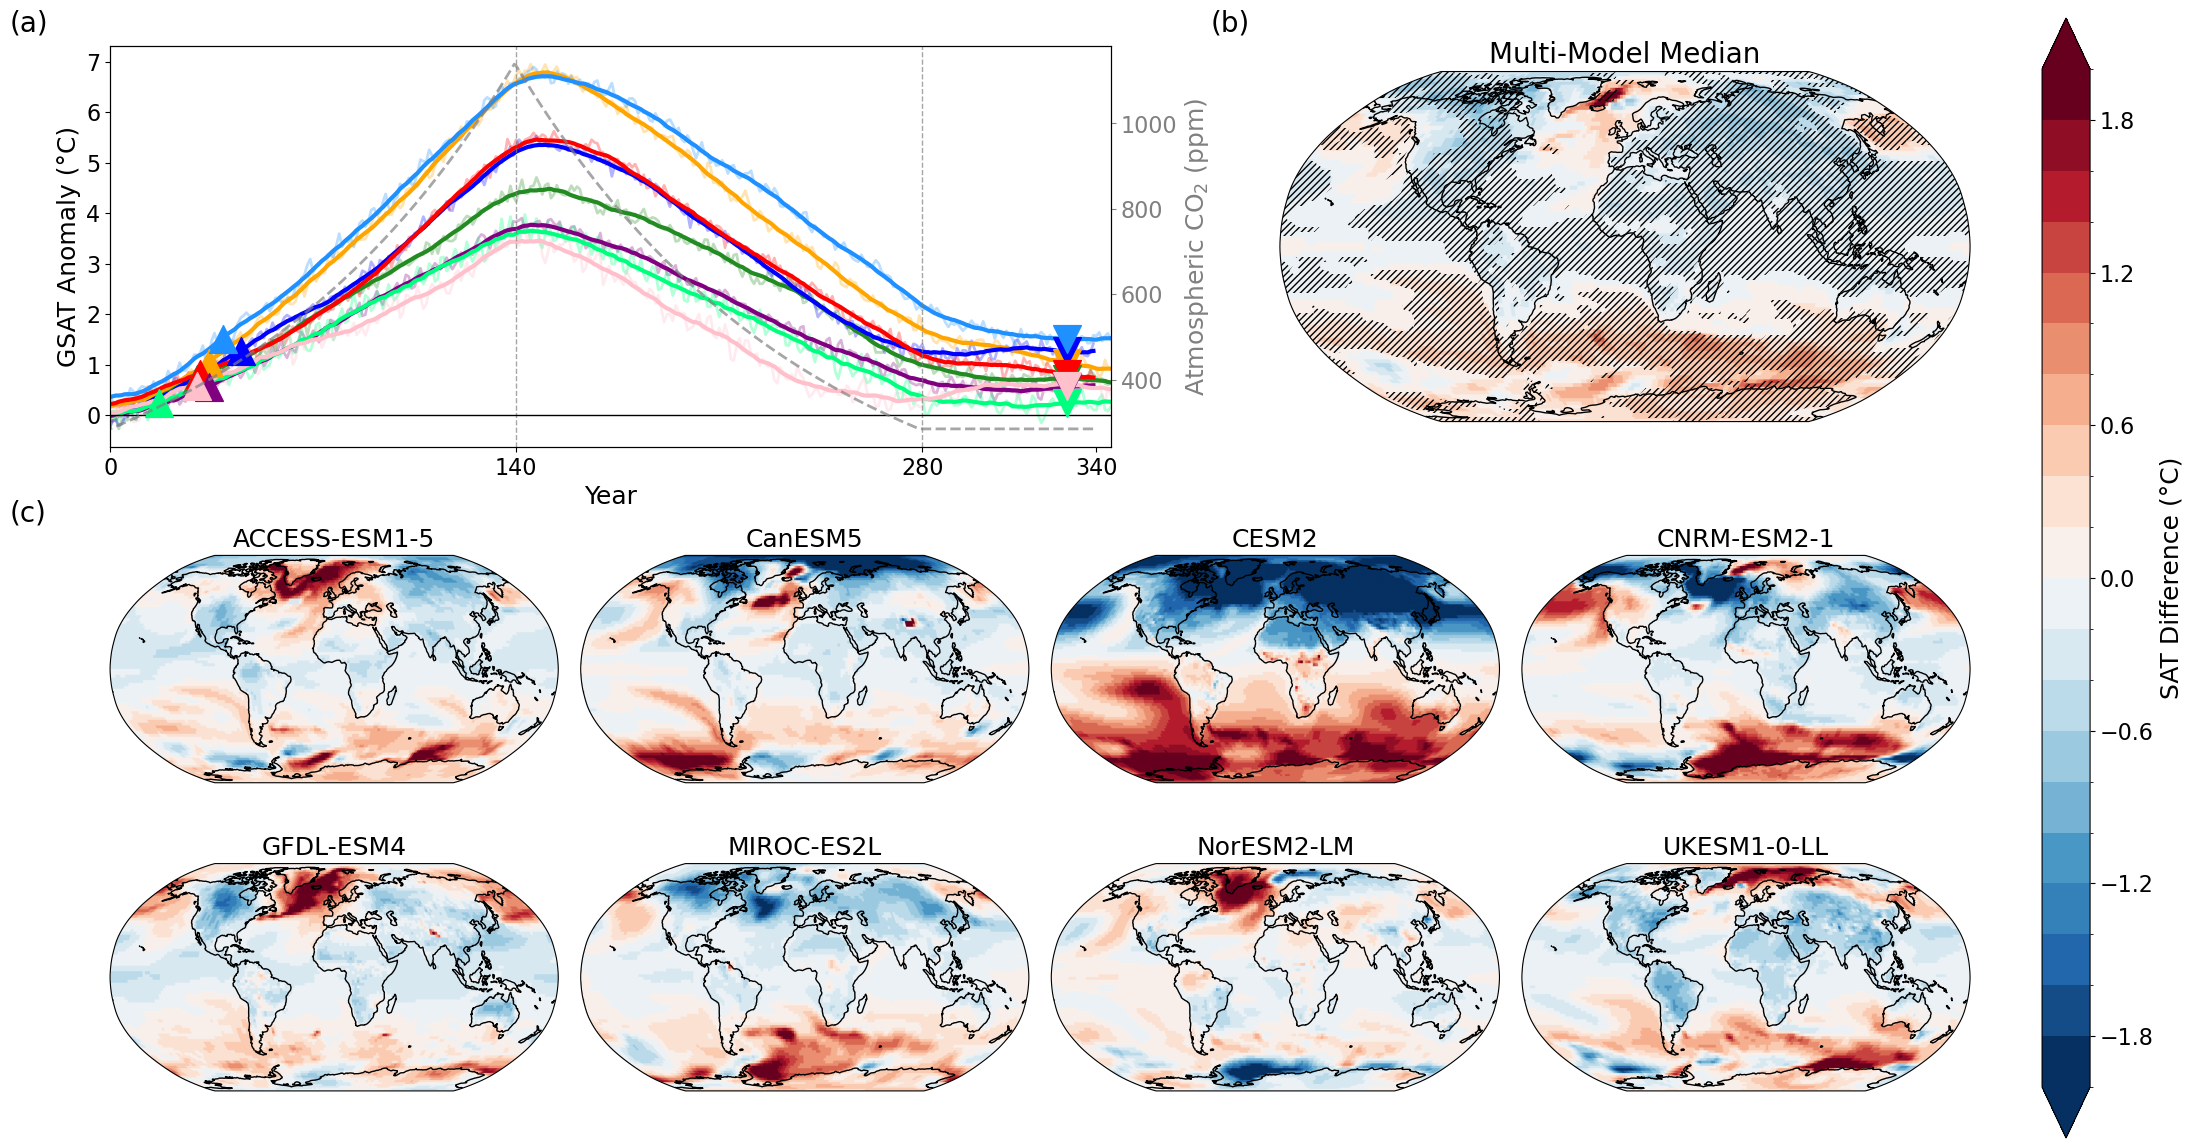

In [8]:
fig = pl.plot_gwl_diff_with_timeseries(
    gsat_rolling,
    sat_diff_final,
    colour_dict,
    raw_tree=gsat,
    gwl_matching_years=gwl_matching_years,
    agreement = sat_diff_agreement_final,
    gwl=None,
    period='final',
    co2=co2,
    fig_dir = FIG_DIR, folder = 'supplementary', file_name = 'figure_S32.jpg'
)

### Regional Reversibility Relative to the Global Average
Here we want to create a map of peak warming relative to the CO2 peak (year 140) (i.e. how many years post peak warming does the peak come?) and with a divergent colormap centred on the gsat peak (i.e. red will indicate the local peak is after peak GSAT and blue indicates the local peak precedes peak GSAT).

<br>
So first step is to calculate local peak warming

In [8]:
peak_warming = io_disk.load_peak_warming(
    'CDRMIP',
    PROC_DIR
)
peak_warming

{'ACCESS-ESM1-5': {'1pctCO2-cdr': {'r1i1p1f1': {'peak': 4.48,
    'peak_year': 152}}},
 'CESM2': {'1pctCO2-cdr': {'r1i1p1f1': {'peak': 5.35, 'peak_year': 150}}},
 'CNRM-ESM2-1': {'1pctCO2-cdr': {'r1i1p1f2': {'peak': 5.46,
    'peak_year': 147}}},
 'CanESM5': {'1pctCO2-cdr': {'r1i1p2f1': {'peak': 6.78, 'peak_year': 150}}},
 'GFDL-ESM4': {'1pctCO2-cdr': {'r1i1p1f1': {'peak': 3.77, 'peak_year': 145}}},
 'MIROC-ES2L': {'1pctCO2-cdr': {'r1i1p1f2': {'peak': 3.65, 'peak_year': 145}}},
 'NorESM2-LM': {'1pctCO2-cdr': {'r1i1p1f1': {'peak': 3.45, 'peak_year': 148}}},
 'UKESM1-0-LL': {'1pctCO2-cdr': {'r1i1p1f2': {'peak': 6.71,
    'peak_year': 149}}}}

In [15]:
def reduce_peaks(peaks, expt, reduction=np.median):
    """
    """
    reduce = lambda dicts: {k: float(reduction([d[k] for d in dicts])) for k in dicts[0]}
    out = {model: reduce(list(expts[expt].values())) for model, expts in peaks.items()}
    out["multi_model_median"] = reduce(list(out.values()))
    return out

def local_peak_year(ds, var="tas", window=21):
    """Year of maximum rolling-mean `var` at each grid point."""
    return stats._rolling_mean(ds[var], window=window, time_dim="year").idxmax(dim="year")

tas_anom = io_disk.load_tree(PROC_DIR, "tas", "CDRMIP", model_order=CDR_MODELS, category="anomaly")
peak_years = utils.reduce_models(
    utils.reduce_member_tree(utils.map_nested(local_peak_year, tas_anom))
)
peak_gsat = reduce_peaks(peak_warming, "1pctCO2-cdr")

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S8.jpg


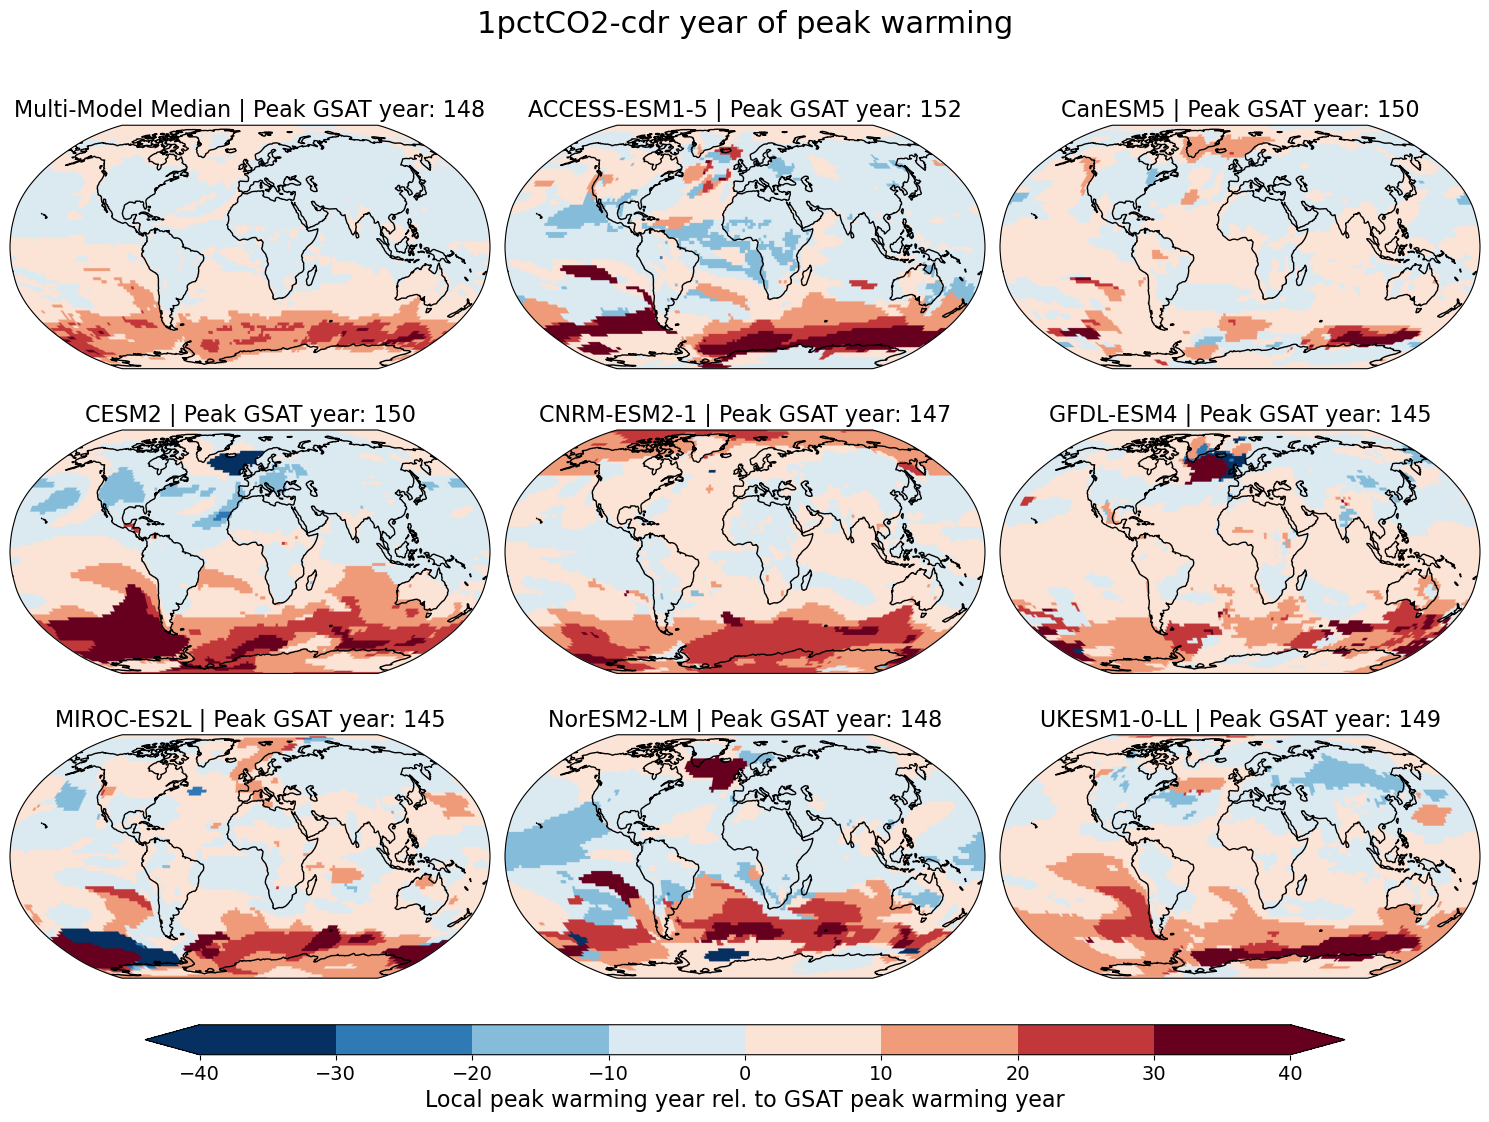

In [33]:
fig = pl.plot_peak_warming_years(
    peak_years,
    peak_gsat,
    expt='1pctCO2-cdr',
    levels = np.arange(-40,41,10),
    fig_dir=FIG_DIR,folder='supplementary',file_name='figure_S8.jpg'
)

## Reversibility map at same co2 level (let's say half way down/up, year 70 vs 210)

In [26]:
reversibility = utils.reduce_models(utils.reduce_member_tree(utils.map_nested(
    lambda ds: stats.branch_difference(stats._rolling_mean(ds.tas, 21, time_dim="year")), tas_anom)))
reversibility_gsat = utils.reduce_models(utils.map_nested(
    lambda ds: stats.branch_difference(ds.gsat), gsat_rolling))

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S9.jpg


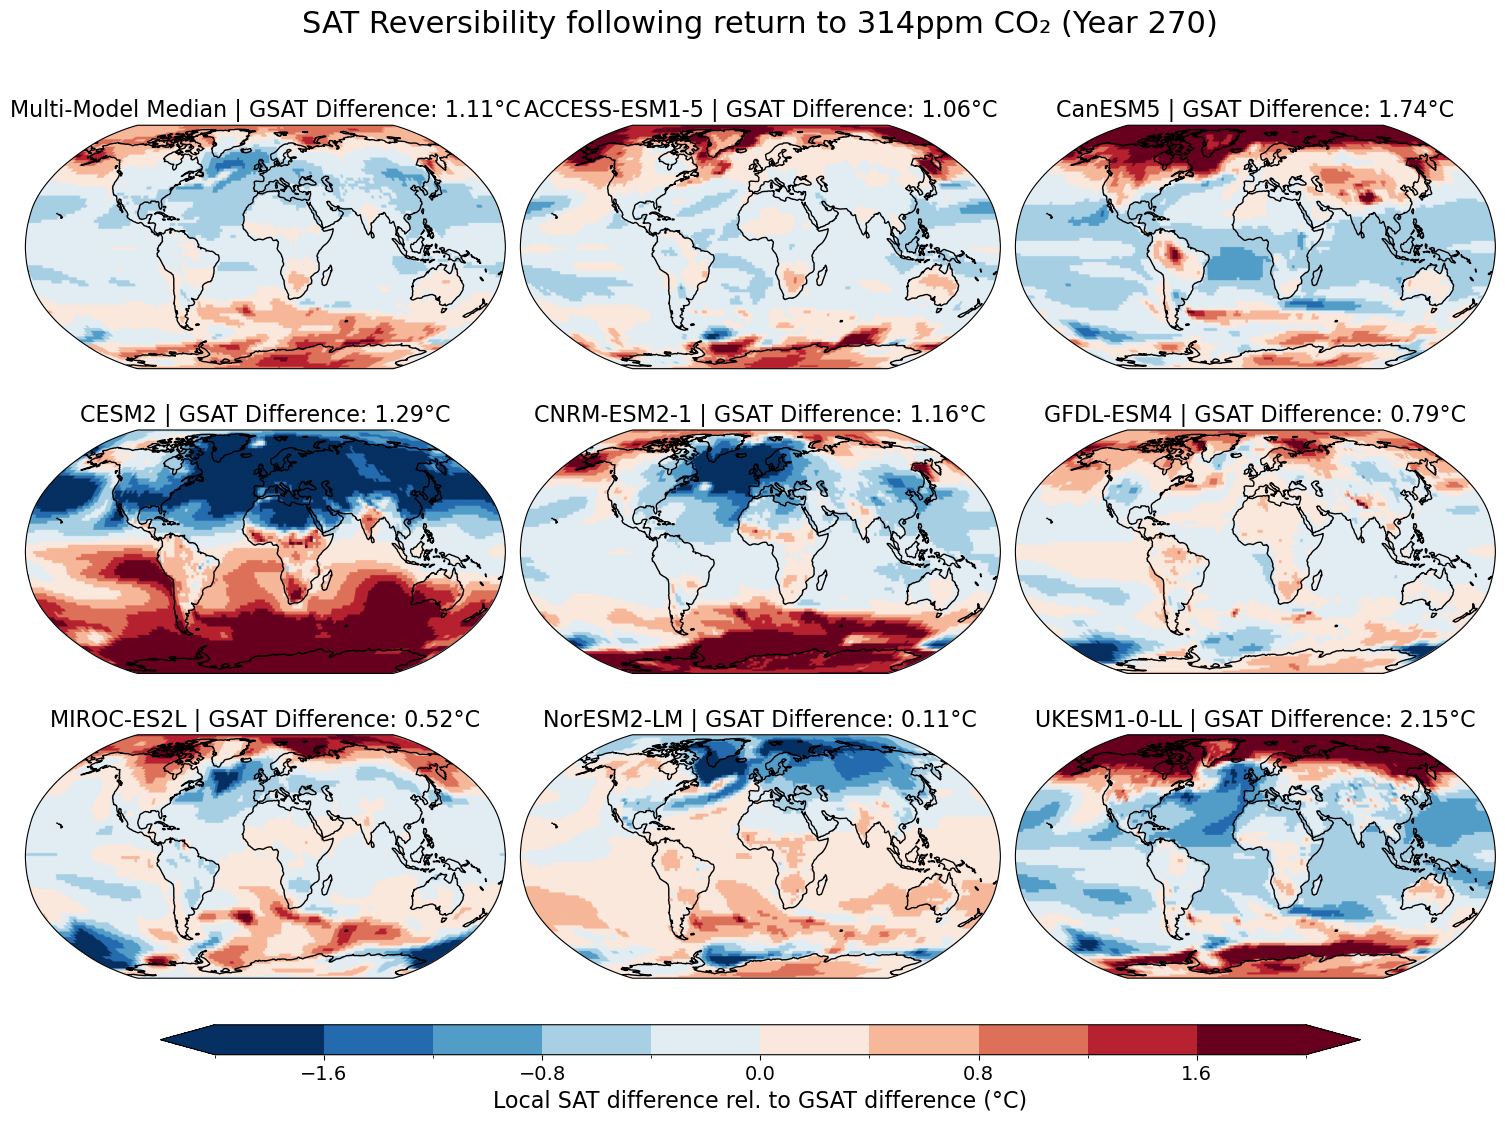

In [34]:
fig = pl.plot_reversibility_rel_gsat_normalised(
    reversibility, reversibility_gsat, window=2, bins=11, rev_year=10,
    expt="1pctCO2-cdr", CO2=CO2,
    fig_dir=FIG_DIR,folder='supplementary',file_name='figure_S9.jpg'
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S10.jpg


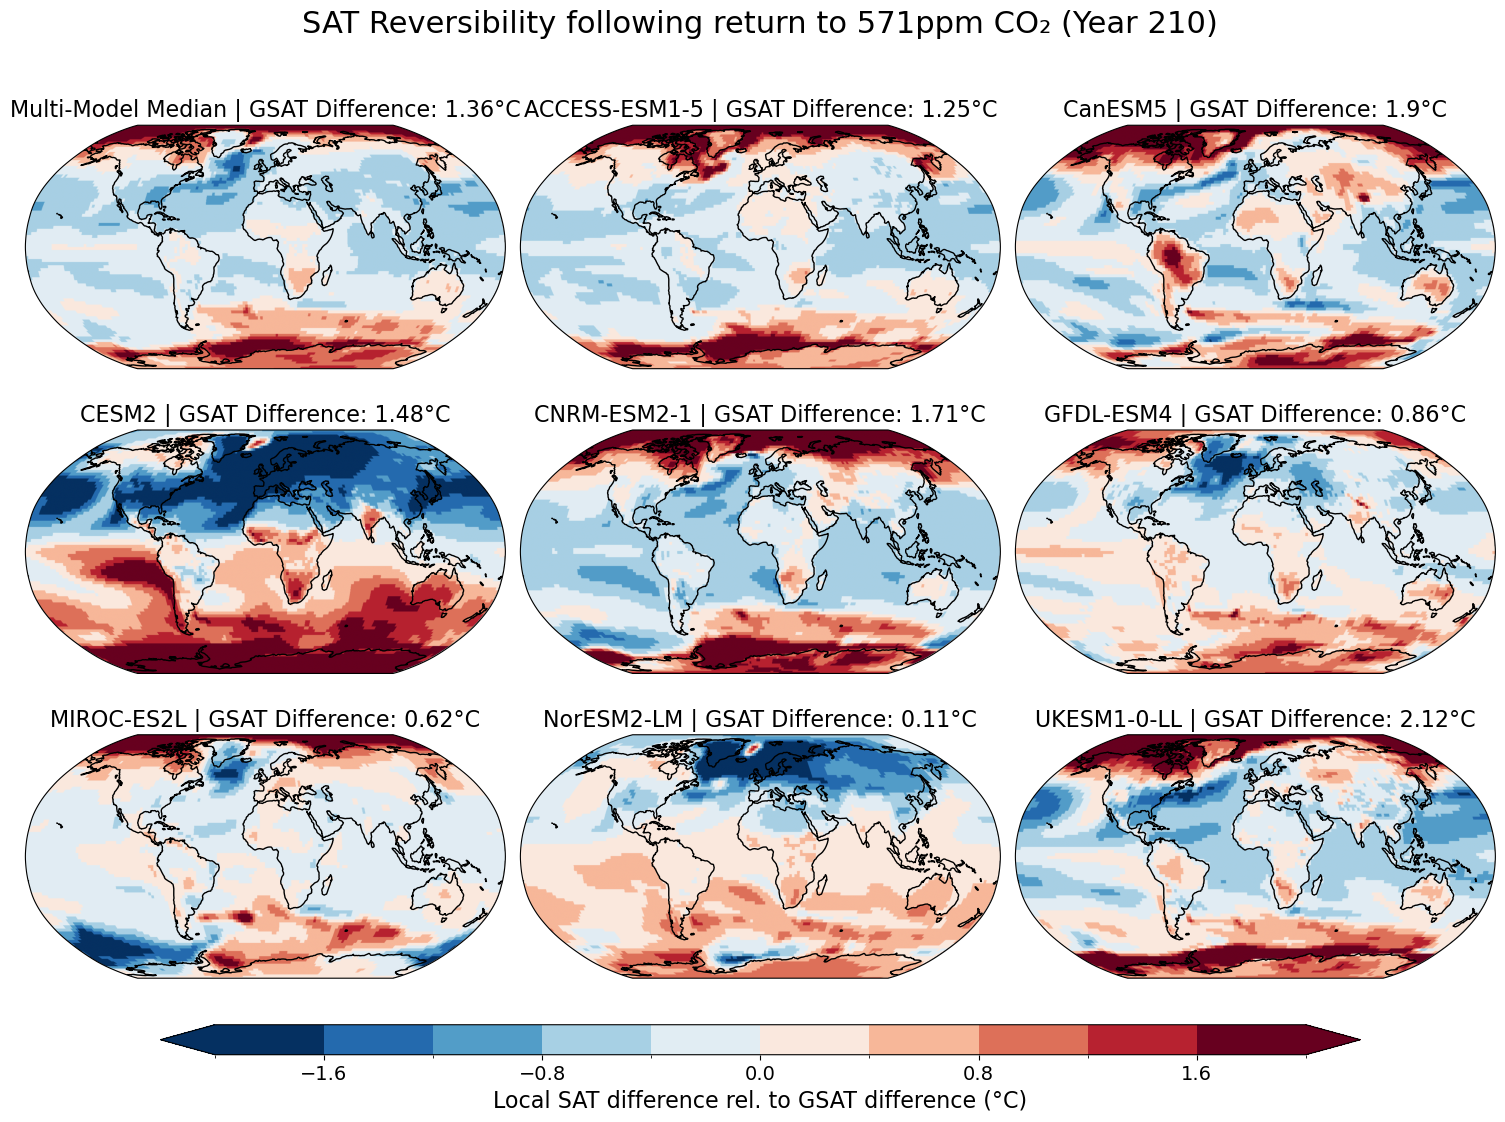

In [35]:
fig = pl.plot_reversibility_rel_gsat_normalised(
    reversibility, reversibility_gsat, window=2, bins=11, rev_year=70,
    expt="1pctCO2-cdr", CO2=CO2,
    fig_dir=FIG_DIR,folder='supplementary',file_name='figure_S10.jpg'
)